In [ ]:
import matplotlib.pyplot as plt
import os
import sys
import time
import socket
import threading
import csv
import numpy as np

from datetime import datetime
from ctypes import c_int16, c_int32, byref, c_char_p, c_float

from numpy.core.function_base import linspace
from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok


# ---------------------------------------------------------------------
# Local component imports
# ---------------------------------------------------------------------

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

import Components as comp


# ---------------------------------------------------------------------
# Hardware setup
# ---------------------------------------------------------------------

laser = comp.Toptica_Laser()


powermeter = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0046773::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)
# ---------------------------------------------------------------------
# Utility functions
# ---------------------------------------------------------------------

def make_data_folder(base_directory='D:/Data'):
    year = datetime.now().strftime('%Y')
    year_month = datetime.now().strftime('%Y%m')
    year_month_day = datetime.now().strftime('%Y%m%d')

    folder_path = os.path.join(
        base_directory,
        year,
        year_month,
        year_month_day
    )

    os.makedirs(folder_path, exist_ok=True)
    return folder_path


def format_for_filename(x):
    """Keep decimal points in filenames but remove spaces."""
    return str(x).strip().replace(" ", "")


def save_arrays(
        voltage_array,
        time_array,
        commanded_power_mW,
        measured_power_uW,
        iteration,
        gain_value,
        base_directory='D:/Data',
        save_time_once=True
):
    folder_path = make_data_folder(base_directory)
    timestamp = datetime.now().strftime('%H%M%S')

    laserp_str = f"{commanded_power_mW:.3g}"
    measp_str = f"{measured_power_uW:.3g}"
    gain_str = format_for_filename(gain_value)

    suffix = (
        f"laserp_{laserp_str}_mW"
        f"_measp_{measp_str}_uW"
        f"_iter{iteration:03d}"
        f"_gain_{gain_str}"
    )

    voltage_filename = f"pbec_{timestamp}_{suffix}_Voltage.txt"
    voltage_path = os.path.join(folder_path, voltage_filename)

    np.savetxt(voltage_path, voltage_array, fmt='%0.4f')

    time_path = None

    if save_time_once:
        time_filename = "pbec_Time.txt"
        time_path = os.path.join(folder_path, time_filename)

        if not os.path.exists(time_path):
            np.savetxt(time_path, time_array, fmt='%0.4f')

    return voltage_path, time_path

power_output_list =[]
power_list = np.arange(0,30,2)/1000

for x in power_list:
    print('Power is :',x*1000)
    laser.set(x)
    power_reading = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
    power_output_list.append(np.mean(np.array(power_reading)))


print(power_list)
print(power_output_list)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)

power_output_list = []
power_output_list_y = []
#get list of power around power threshhold

In [3]:

def getpowerarray(pth):
    powerarray1 = [0,0.3*pth,0.7*pth]
    powerarray2 = np.linspace(0.9*pth,1.3*pth,31)
    powerarray3 = [1.4*pth,1.5*pth,1.8*pth]

    powerarray = np.concatenate((powerarray1,powerarray2,powerarray3))/1000
    return powerarray



Power is : 0.0
Power is : 14.1
Power is : 32.9
Power is : 42.300000000000004
Power is : 42.92666666666667
Power is : 43.553333333333335
Power is : 44.18000000000001
Power is : 44.80666666666667
Power is : 45.43333333333334
Power is : 46.06
Power is : 46.68666666666667
Power is : 47.31333333333334
Power is : 47.940000000000005
Power is : 48.56666666666667
Power is : 49.193333333333335
Power is : 49.82000000000001
Power is : 50.44666666666667
Power is : 51.07333333333334
Power is : 51.7
Power is : 52.32666666666667
Power is : 52.95333333333333
Power is : 53.580000000000005
Power is : 54.20666666666667
Power is : 54.833333333333336
Power is : 55.46
Power is : 56.08666666666667
Power is : 56.71333333333334
Power is : 57.34
Power is : 57.96666666666667
Power is : 58.593333333333334
Power is : 59.22
Power is : 59.846666666666664
Power is : 60.473333333333336
Power is : 61.1
Power is : 65.8
Power is : 70.5
Power is : 84.60000000000001
[0.         0.0141     0.0329     0.0423     0.04292667 0.

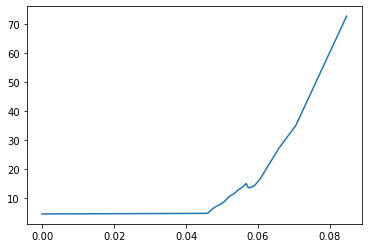

In [7]:
power_output_list = []


power_list = getpowerarray(47) #W
for x in power_list:
    print('Power is :',x*1000)
    laser.set(x)
    power_reading = []
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
    power_output_list.append(np.mean(np.array(power_reading)))

print(power_list)
print(power_output_list)
laser.set(0)
import matplotlib.pyplot as plt
plt.plot(power_list, power_output_list)